<a href="https://colab.research.google.com/github/fhnahid112/AI/blob/main/SMS_Spam_SVM_Improved_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# SMS Spam Classification using SVM (Improved)
Dataset: https://www.kaggle.com/datasets/uciml/sms-spam-collection-dataset?resource=download

### What is improved compared with the original notebook
| # | Improvement | Why it helps |
|---|---|---|
| 1 | **Character n-gram TF-IDF** (in addition to word TF-IDF) | Catches obfuscated spelling such as `fr33`, `txt`, `c@ll` |
| 2 | **Hand-made meta features** (currency symbol, digits, phone number, CAPS, `!`, URL, length) | The original cleaning deleted digits and punctuation, which are strong spam signals |
| 3 | **`class_weight` search** | Spam is only ~13% of the data; missed spam is penalised more |
| 4 | **Wider grid search** (`C`, class weight, word n-grams) scored on **F1** | Accuracy alone is misleading on imbalanced data |
| 5 | **Threshold tuning** using cross-validated scores on the training set only | Trades precision against recall in a principled way (no test-set peeking) |
| 6 | **Baseline vs improved comparison**, confusion matrix, PR/ROC, error analysis, top features | Shows *what* improved and *why* |
| 7 | **Model saved** with `joblib` | Can be reused without retraining |

In [ ]:
# Install (if needed). %pip installs into the same Python that runs this notebook.
# If anything gets installed, restart the kernel once (Kernel > Restart) and run the cells again.
%pip -q install pandas numpy matplotlib seaborn wordcloud nltk scikit-learn joblib

In [ ]:
import os, re, string, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import nltk

from wordcloud import WordCloud
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             precision_recall_curve, average_precision_score, roc_curve, auc)

warnings.filterwarnings("ignore")
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)

True

## Upload dataset (`SMS.csv` / `spam.csv`) downloaded from Kaggle.

In [ ]:
# On Google Colab: upload the file. Elsewhere: just place the CSV next to this notebook.
import glob

def find_dataset():
    # Accepts SMS.csv, spam.csv, "spam (1).csv", etc. (any CSV with "spam" or "sms" in its name)
    return next((f for f in sorted(glob.glob("*.csv")) if any(k in f.lower() for k in ("spam", "sms"))), None)

try:
    from google.colab import files
    if find_dataset() is None:
        files.upload()
except ImportError:
    pass

FILE = find_dataset()
if FILE is None:
    raise FileNotFoundError("Dataset not found. Put the Kaggle CSV (SMS.csv or spam.csv) in this folder.")
print("Using file:", FILE)

df = pd.read_csv(FILE, encoding="latin-1")
df = df[['v1', 'v2']]
df.columns = ['label', 'message']

Saving spam.csv to spam.csv
Using file: spam.csv


In [ ]:
print(df.shape)
print(df.info())
print(df.isnull().sum())
print("Duplicates:", df.duplicated().sum())
print(df['label'].value_counts())

(5572, 2)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   label    5572 non-null   object
 1   message  5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB
None
label      0
message    0
dtype: int64
Duplicates: 403
label
ham     4825
spam     747
Name: count, dtype: int64


## Exploratory Data Analysis

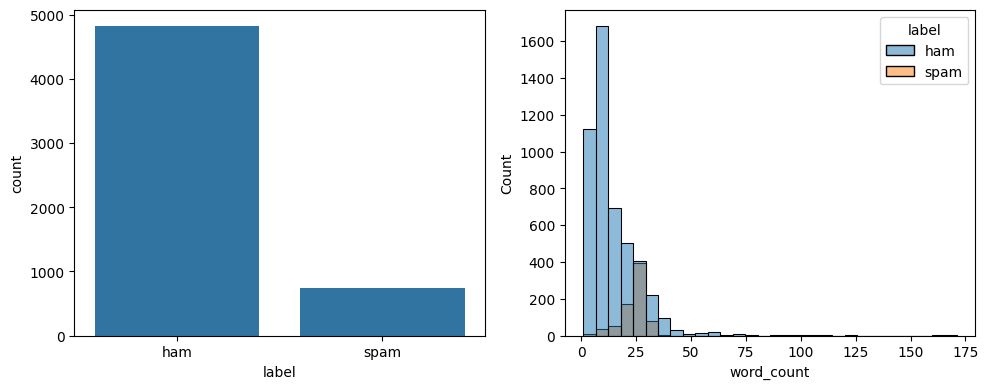

In [ ]:
df['char_count'] = df['message'].str.len()
df['word_count'] = df['message'].str.split().str.len()

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.countplot(data=df, x='label', ax=ax[0])
sns.histplot(data=df, x='word_count', hue='label', bins=30, ax=ax[1])
plt.tight_layout()
plt.show()

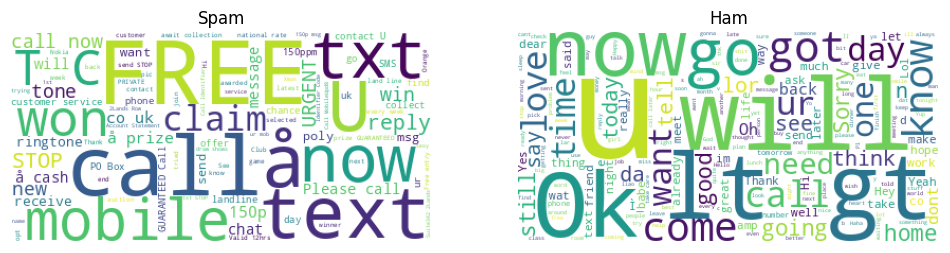

In [ ]:
spam = ' '.join(df[df.label == 'spam'].message)
ham = ' '.join(df[df.label == 'ham'].message)

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.imshow(WordCloud(background_color='white').generate(spam))
plt.axis('off'); plt.title("Spam")
plt.subplot(1, 2, 2)
plt.imshow(WordCloud(background_color='white').generate(ham))
plt.axis('off'); plt.title("Ham")
plt.show()

## Preprocessing
The cleaned text (`clean_message`) is kept for the **word-level** features.
The **raw** text (`message`) is kept as well, because digits, `£`, `!` and CAPS carry spam signals
that the cleaning step removes. The new feature blocks below read the raw text.

In [ ]:
stop_words = set(stopwords.words('english'))
lemm = WordNetLemmatizer()

def clean_text(text):
    text = text.lower()
    text = re.sub(r'http\S+|www\S+', ' ', text)      # URLs
    text = re.sub(r'\S+@\S+', ' ', text)              # e-mail addresses
    text = re.sub(r'\d+', ' ', text)                  # digits
    text = text.translate(str.maketrans('', '', string.punctuation))
    tokens = [lemm.lemmatize(w) for w in text.split() if w not in stop_words]
    return ' '.join(tokens)

# Remove duplicate SMS messages
df = df.drop_duplicates(subset=['label', 'message']).reset_index(drop=True)

df['clean_message'] = df['message'].apply(clean_text)
df['label'] = df['label'].map({'ham': 0, 'spam': 1})

df[['label', 'message', 'clean_message']].head()

,label,message,clean_message
0,0,"Go until jurong point, crazy.. Available only ...",go jurong point crazy available bugis n great ...
1,0,Ok lar... Joking wif u oni...,ok lar joking wif u oni
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,free entry wkly comp win fa cup final tkts st ...
3,0,U dun say so early hor... U c already then say...,u dun say early hor u c already say
4,0,"Nah I don't think he goes to usf, he lives aro...",nah dont think go usf life around though


## Train/Test Split

In [ ]:
X = df[['message', 'clean_message']]   # a DataFrame now: raw + cleaned text
y = df['label']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(X_train.shape, X_test.shape)
print("Spam share  train: %.3f | test: %.3f" % (y_train.mean(), y_test.mean()))

(4135, 2) (1034, 2)
Spam share  train: 0.126 | test: 0.127


## Baseline model (the original notebook)
Kept here so the improvement can be measured on the **same split**.

In [ ]:
results = {}

def evaluate(name, y_true, y_pred):
    results[name] = {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Recall": recall_score(y_true, y_pred),
        "F1": f1_score(y_true, y_pred),
        "Missed spam (FN)": int(((y_true == 1) & (y_pred == 0)).sum()),
        "False alarms (FP)": int(((y_true == 0) & (y_pred == 1)).sum()),
    }

baseline = Pipeline([
    ('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1, 2))),
    ('svm', LinearSVC())
])
baseline.fit(X_train['clean_message'], y_train)
evaluate("Baseline (original)", y_test, baseline.predict(X_test['clean_message']))
pd.DataFrame(results).T.round(4)

,Accuracy,Precision,Recall,F1,Missed spam (FN),False alarms (FP)
Baseline (original),0.9845,0.9832,0.8931,0.936,14.0,2.0


## Improved feature engineering
Three feature blocks are stacked side by side:

1. **Word TF-IDF** on the cleaned text
2. **Character n-gram TF-IDF** on the raw text (robust to spelling tricks)
3. **Meta features** on the raw text (currency, digits, phone number, CAPS, `!`, URL, length)

In [ ]:
def meta_features(s):
    s = pd.Series(s).astype(str)
    length = s.str.len().clip(lower=1)
    return pd.DataFrame({
        'log_chars':     np.log1p(s.str.len()),
        'log_words':     np.log1p(s.str.split().str.len()),
        'log_digits':    np.log1p(s.str.count(r'\d')),
        'digit_ratio':   s.str.count(r'\d') / length,
        'upper_ratio':   s.apply(lambda t: sum(c.isupper() for c in t)) / length,
        'n_caps_words':  s.str.count(r'\b[A-Z]{2,}\b'),
        'n_exclaim':     s.str.count('!'),
        'has_currency':  s.str.contains(r'[£$€]').astype(int),
        'has_url':       s.str.contains(r'http|www\.|\.com|\.co\.uk', case=False).astype(int),
        'has_phone':     s.str.contains(r'\b\d{9,}\b').astype(int),
        'has_shortcode': s.str.contains(r'\b\d{4,6}\b').astype(int),
    })

META_NAMES = list(meta_features(["a"]).columns)

def meta_names_out(transformer, input_features):
    return np.array(META_NAMES)

features = ColumnTransformer([
    ('word', TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True), 'clean_message'),
    ('char', TfidfVectorizer(analyzer='char_wb', ngram_range=(2, 5), min_df=3, sublinear_tf=True), 'message'),
    ('meta', Pipeline([('make', FunctionTransformer(meta_features, feature_names_out=meta_names_out)),
                       ('scale', StandardScaler())]), 'message'),
])

# Quick look at the meta features for a typical spam message
meta_features(["WINNER!! You have won £1000. Call 09061701461 now"]).T

,0
log_chars,3.912023
log_words,2.197225
log_digits,2.772589
digit_ratio,0.306122
upper_ratio,0.163265
n_caps_words,1.000000
n_exclaim,2.000000
has_currency,1.000000
has_url,0.000000
has_phone,1.000000


## Hyperparameter Tuning
Grid search over `C`, class weights and the word n-gram range.
Scoring uses **F1 of the spam class** (with accuracy tracked as well), and the model is refit on the best F1 setting.

In [ ]:
pipeline = Pipeline([
    ('features', features),
    ('svm', LinearSVC(max_iter=10000))
])

param_grid = {
    'svm__C': [0.1, 0.3, 1, 3, 10],
    'svm__class_weight': [None, 'balanced'],
    'features__word__ngram_range': [(1, 1), (1, 2)],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

grid = GridSearchCV(
    pipeline, param_grid, cv=cv,
    scoring={'f1': 'f1', 'accuracy': 'accuracy'}, refit='f1',
    n_jobs=-1
)
grid.fit(X_train, y_train)

print("Best parameters :", grid.best_params_)
print("Best CV F1      : %.4f" % grid.best_score_)
best_idx = grid.best_index_
print("CV accuracy there: %.4f" % grid.cv_results_['mean_test_accuracy'][best_idx])

model = grid.best_estimator_

Best parameters : {'features__word__ngram_range': (1, 2), 'svm__C': 3, 'svm__class_weight': 'balanced'}
Best CV F1      : 0.9545
CV accuracy there: 0.9886


## Evaluation on the held-out test set

In [ ]:
pred = model.predict(X_test)
evaluate("Improved (default threshold)", y_test, pred)

print(classification_report(y_test, pred, target_names=['ham', 'spam']))

              precision    recall  f1-score   support

         ham       0.99      1.00      1.00       903
        spam       0.99      0.95      0.97       131

    accuracy                           0.99      1034
   macro avg       0.99      0.97      0.98      1034
weighted avg       0.99      0.99      0.99      1034



## Threshold tuning
`LinearSVC` predicts spam when its score is above 0. A different cut-off may balance precision and recall better.
The threshold is chosen using **cross-validated scores on the training set only**, so the test set stays untouched.

Out-of-fold F1 at 0.0: 0.9544 | best: 0.9549 at t=-0.22
Threshold used: 0.0


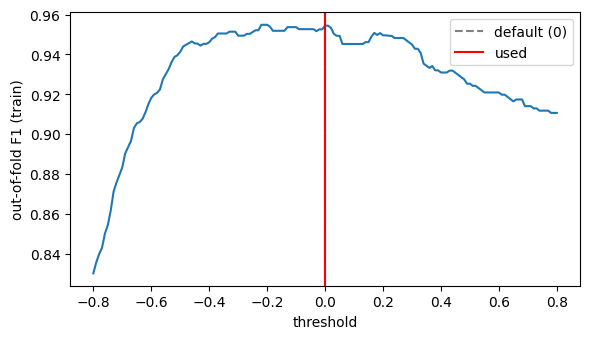

In [ ]:
# Out-of-fold decision scores on the training set
oof_scores = cross_val_predict(model, X_train, y_train, cv=cv, method='decision_function', n_jobs=-1)

thresholds = np.linspace(-0.8, 0.8, 161)
f1_by_t = [f1_score(y_train, (oof_scores > t).astype(int)) for t in thresholds]
best_t = thresholds[int(np.argmax(f1_by_t))]
f1_at_zero = f1_score(y_train, (oof_scores > 0).astype(int))

# Only move the threshold if it clearly beats the default (guards against overfitting noise)
THRESHOLD = best_t if max(f1_by_t) - f1_at_zero > 0.002 else 0.0
print("Out-of-fold F1 at 0.0: %.4f | best: %.4f at t=%.2f" % (f1_at_zero, max(f1_by_t), best_t))
print("Threshold used:", round(float(THRESHOLD), 2))

plt.figure(figsize=(6, 3.5))
plt.plot(thresholds, f1_by_t)
plt.axvline(0, ls='--', c='grey', label='default (0)')
plt.axvline(THRESHOLD, c='red', label='used')
plt.xlabel('threshold'); plt.ylabel('out-of-fold F1 (train)'); plt.legend()
plt.tight_layout(); plt.show()

test_scores = model.decision_function(X_test)
pred_final = (test_scores > THRESHOLD).astype(int)
evaluate("Improved (final)", y_test, pred_final)

## Confusion matrix, Precision-Recall and ROC curves

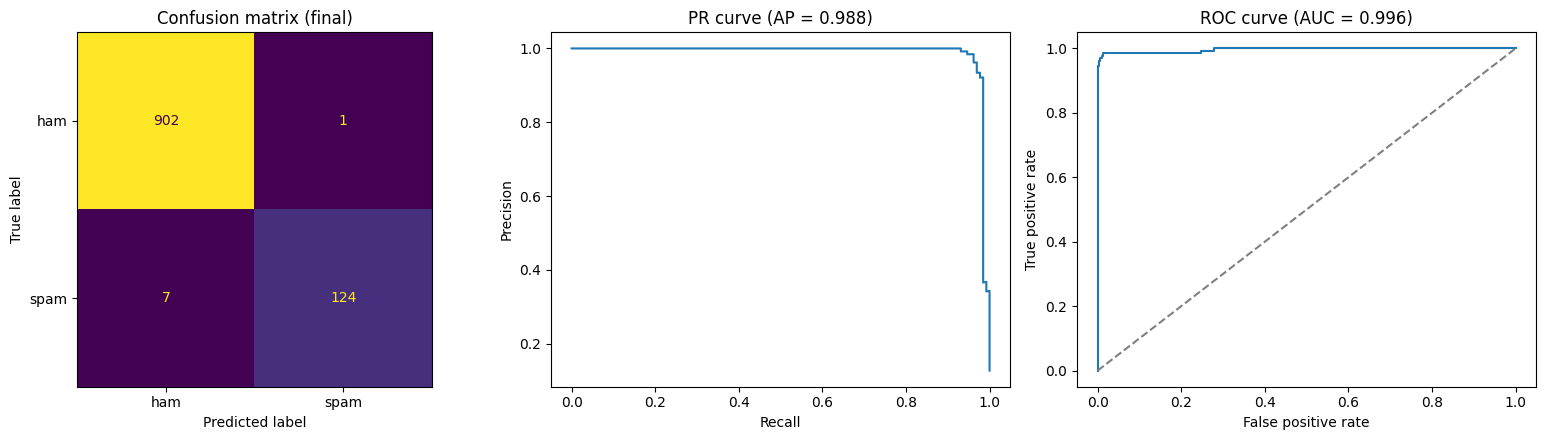

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))

ConfusionMatrixDisplay(confusion_matrix(y_test, pred_final),
                       display_labels=['ham', 'spam']).plot(ax=ax[0], colorbar=False)
ax[0].set_title("Confusion matrix (final)")

p, r, _ = precision_recall_curve(y_test, test_scores)
ax[1].plot(r, p)
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision")
ax[1].set_title("PR curve (AP = %.3f)" % average_precision_score(y_test, test_scores))

fpr, tpr, _ = roc_curve(y_test, test_scores)
ax[2].plot(fpr, tpr); ax[2].plot([0, 1], [0, 1], '--', c='grey')
ax[2].set_xlabel("False positive rate"); ax[2].set_ylabel("True positive rate")
ax[2].set_title("ROC curve (AUC = %.3f)" % auc(fpr, tpr))

plt.tight_layout(); plt.show()

## Baseline vs Improved

In [ ]:
comparison = pd.DataFrame(results).T
comparison[["Accuracy", "Precision", "Recall", "F1"]] = comparison[["Accuracy", "Precision", "Recall", "F1"]].round(4)
comparison

,Accuracy,Precision,Recall,F1,Missed spam (FN),False alarms (FP)
Baseline (original),0.9845,0.9832,0.8931,0.9360,14.0,2.0
Improved (default threshold),0.9923,0.9920,0.9466,0.9688,7.0,1.0
Improved (final),0.9923,0.9920,0.9466,0.9688,7.0,1.0


## Cross Validation (5-fold, whole dataset)

In [ ]:
# Note: the hyper-parameters were chosen on the training split, so this is a mild-optimism estimate.
# The held-out test result above is the cleaner final number.
cv_full = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

base_cv = cross_val_score(
    Pipeline([('tfidf', TfidfVectorizer(max_features=5000, ngram_range=(1, 2))), ('svm', LinearSVC())]),
    df['clean_message'], df['label'], cv=cv_full, scoring='accuracy')

imp_cv = cross_val_score(model, X, y, cv=cv_full, scoring='accuracy', n_jobs=-1)

print("Baseline CV accuracy:", base_cv.round(4), "| mean = %.4f" % base_cv.mean())
print("Improved CV accuracy:", imp_cv.round(4), "| mean = %.4f" % imp_cv.mean())

Baseline CV accuracy: [0.9778 0.9865 0.9778 0.9807 0.9826] | mean = 0.9810
Improved CV accuracy: [0.9894 0.9884 0.9884 0.9894 0.9913] | mean = 0.9894


## Error analysis: which messages are still wrong?

In [ ]:
errors = X_test.copy()
errors['true'] = y_test.map({0: 'ham', 1: 'spam'})
errors['predicted'] = pd.Series(pred_final, index=X_test.index).map({0: 'ham', 1: 'spam'})
errors['score'] = test_scores.round(2)
errors = errors[errors['true'] != errors['predicted']]

pd.set_option('display.max_colwidth', 140)
errors[['true', 'predicted', 'score', 'message']].sort_values('score')

,true,predicted,score,message
1812,spam,ham,-1.21,Would you like to see my XXX pics they are so hot they were nearly banned in the uk!
5062,spam,ham,-1.17,"Latest News! Police station toilet stolen, cops have nothing to go on!"
2641,spam,ham,-0.46,Burger King - Wanna play footy at a top stadium? Get 2 Burger King before 1st Sept and go Large or Super with Coca-Cola and walk out a w...
4497,spam,ham,-0.40,Check Out Choose Your Babe Videos @ sms.shsex.netUN fgkslpoPW fgkslpo
660,spam,ham,-0.28,SMS. ac sun0819 posts HELLO:\You seem cool
2302,spam,ham,-0.19,Babe: U want me dont u baby! Im nasty and have a thing 4 filthyguys. Fancy a rude time with a sexy bitch. How about we go slo n hard! Tx...
3330,spam,ham,-0.15,"Xmas & New Years Eve tickets are now on sale from the club, during the day from 10am till 8pm, and on Thurs, Fri & Sat night this week. ..."
1252,ham,spam,0.12,"Hey...Great deal...Farm tour 9am to 5pm $95/pax, $50 deposit by 16 May"


## Which features matter most?

In [ ]:
names = model.named_steps['features'].get_feature_names_out()
coefs = model.named_steps['svm'].coef_.ravel()
imp = pd.DataFrame({'feature': names, 'coef': coefs}).sort_values('coef')

print("Strongest SPAM indicators")
print(imp.tail(15).iloc[::-1].to_string(index=False))
print("\nStrongest HAM indicators")
print(imp.head(10).to_string(index=False))
print("\nMeta features")
print(imp[imp.feature.str.startswith('meta__')].sort_values('coef', ascending=False).to_string(index=False))

Strongest SPAM indicators
           feature     coef
        word__text 1.038813
     word__arsenal 0.835836
     word__brought 0.821465
         word__ltd 0.812471
      word__mobile 0.772817
     word__divorce 0.763844
        word__real 0.636301
   word__tell look 0.621354
word__girl waiting 0.617211
    word__ringtone 0.606566
        word__free 0.599886
     word__content 0.589031
       word__reply 0.578810
       word__truly 0.578016
      word__filthy 0.573890

Strongest HAM indicators
    feature      coef
  word__air -0.701164
 word__ring -0.683738
 word__ltgt -0.603939
   char__.. -0.450082
word__bedrm -0.442359
word__intro -0.442111
  word__hey -0.403689
  char__my  -0.392968
 char__ my  -0.385611
  word__sat -0.381006

Meta features
            feature      coef
    meta__log_chars  0.441225
   meta__log_digits  0.294278
    meta__has_phone  0.229420
meta__has_shortcode  0.140688
      meta__has_url  0.136662
 meta__has_currency  0.117054
  meta__digit_ratio  0.056683
  m

## Save the model and predict new SMS

In [ ]:
# To reload in a new session, first re-run the cells that define clean_text, meta_features and meta_names_out.
joblib.dump({'model': model, 'threshold': float(THRESHOLD)}, 'spam_svm_improved.joblib')

def predict_sms(text):
    row = pd.DataFrame({'message': [text], 'clean_message': [clean_text(text)]})
    score = float(model.decision_function(row)[0])
    label = "Spam" if score > THRESHOLD else "Ham"
    return label, round(score, 2)

tests = [
    "Congratulations! You have won a free iPhone. Click here now.",
    "Hi, are we meeting tomorrow at 3 PM?",
    "URGENT! Your mobile number has won a £2000 prize. Call 09061701461 now to claim.",
    "Can you send me the notes from today's lecture?",
    "Free entry to win tickets! Text WIN to 80086 now. T&Cs apply.",
]
for t in tests:
    print(predict_sms(t), "->", t)

('Ham', -0.4) -> Congratulations! You have won a free iPhone. Click here now.
('Ham', -1.65) -> Hi, are we meeting tomorrow at 3 PM?
('Spam', 3.08) -> URGENT! Your mobile number has won a £2000 prize. Call 09061701461 now to claim.
('Ham', -1.15) -> Can you send me the notes from today's lecture?
('Spam', 0.96) -> Free entry to win tickets! Text WIN to 80086 now. T&Cs apply.
